<a href="https://colab.research.google.com/github/gomezllari/.json/blob/main/breast_cancer_coimbra_classification_with_eda_ml_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

df_csv = pd.read_csv('dataR2.csv')
df_csv.head() # Mostra as primeiras linhas

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114,1
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786,1
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697,1
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220,1
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920,1


In [3]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download(
    "uciml/breast-cancer-wisconsin-data"
)


df = pd.read_csv(os.path.join(path, "data.csv"))

print(df.head(1)['diagnosis'])
#print(df.shape)
print(df.columns)

df.info()

df["diagnosis"].value_counts()

#exploração dos dados
#normalização dos dados
#separar o treino e teste
#avaliação
#sklean

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
0    M
Name: diagnosis, dtype: object
Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 

,count
diagnosis,
B,357
M,212


In [4]:
# 1. Remover colunas desnecessárias ('id' e a coluna vazia 'Unnamed: 32')
colunas_para_remover = ['id']
if 'Unnamed: 32' in df.columns:
    colunas_para_remover.append('Unnamed: 32')

df_limpo = df.drop(columns=colunas_para_remover)

# 2. Converter a coluna 'diagnosis' (M/B) para números (1 para Maligno, 0 para Benigno)
df_limpo['diagnosis'] = df_limpo['diagnosis'].map({'M': 1, 'B': 0})

# 3. Separar Features (X - as caraterísticas) e Target (y - o diagnóstico)
X = df_limpo.drop(columns=['diagnosis'])
y = df_limpo['diagnosis']

print("Temos agora", X.shape[1], "caraterísticas (features) prontas para treino!")

Temos agora 30 caraterísticas (features) prontas para treino!


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Separar 80% para treino e 20% para teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Normalizar os dados (Regra de ouro: faz-se DEPOIS de separar)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Testar dois modelos exigidos pelo desafio (Random Forest e Regressão Logística)
modelos = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Regressão Logística": LogisticRegression(random_state=42)
}

for nome, modelo in modelos.items():
    print(f"--- Treinando o modelo: {nome} ---")
    modelo.fit(X_train_scaled, y_train)

    # Previsão
    y_pred = modelo.predict(X_test_scaled)

    # Avaliação (Acurácia e Métricas)
    acuracia = accuracy_score(y_test, y_pred)
    print(f"Acurácia: {acuracia * 100:.2f}%\n")
    print(classification_report(y_test, y_pred))
    print("="*40)

--- Treinando o modelo: Random Forest ---
Acurácia: 96.49%

              precision    recall  f1-score   support

           0       0.96      0.99      0.97        71
           1       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

--- Treinando o modelo: Regressão Logística ---
Acurácia: 97.37%

              precision    recall  f1-score   support

           0       0.97      0.99      0.98        71
           1       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn import tree

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_graphviz

In [8]:
dados = df.copy()
dados.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [9]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [10]:
df = df.drop(columns=['Unnamed: 32', 'id'], errors='ignore')

In [11]:
dados = dados.dropna()

/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


<Axes: >

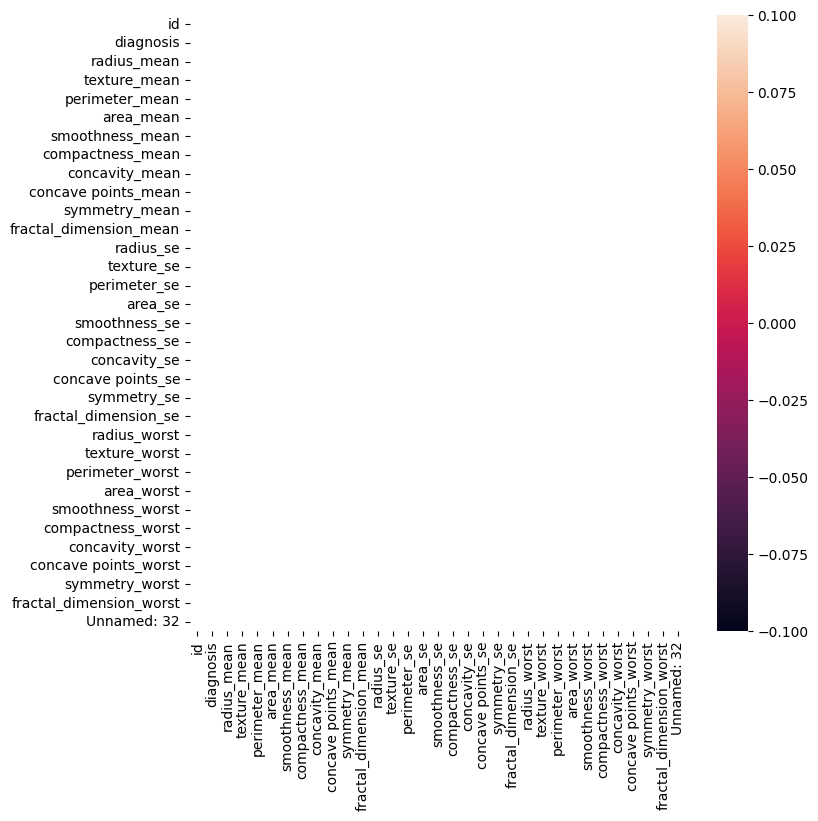

In [12]:
correlation_matrix = dados.corr().round(2)

fig, ax = plt.subplots(figsize=(8,8))
sns.heatmap(data=correlation_matrix, annot=True, linewidths=.5, ax=ax)

In [14]:
# Usando df_csv que contém a coluna 'Classification'
X = df_csv.drop(columns=['Classification'])
y = df_csv['Classification']

In [15]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)

In [16]:
dt = DecisionTreeClassifier(random_state=7, criterion='entropy', max_depth = 2)

In [17]:
dt.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=7)

In [18]:
y_predito = dt.predict(x_test)

[Text(0.5, 0.8333333333333334, 'x[2] <= 91.5\nentropy = 0.991\nsamples = 92\nvalue = [41, 51]'),
 Text(0.25, 0.5, 'x[7] <= 13.248\nentropy = 0.91\nsamples = 40\nvalue = [27, 13]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'entropy = 0.529\nsamples = 25\nvalue = [22, 3]'),
 Text(0.375, 0.16666666666666666, 'entropy = 0.918\nsamples = 15\nvalue = [5, 10]'),
 Text(0.75, 0.5, 'x[0] <= 48.5\nentropy = 0.84\nsamples = 52\nvalue = [14, 38]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'entropy = 0.0\nsamples = 14\nvalue = [0, 14]'),
 Text(0.875, 0.16666666666666666, 'entropy = 0.949\nsamples = 38\nvalue = [14, 24]')]

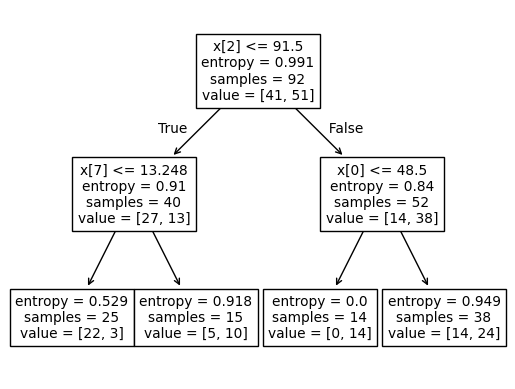

In [19]:
tree.plot_tree(dt)

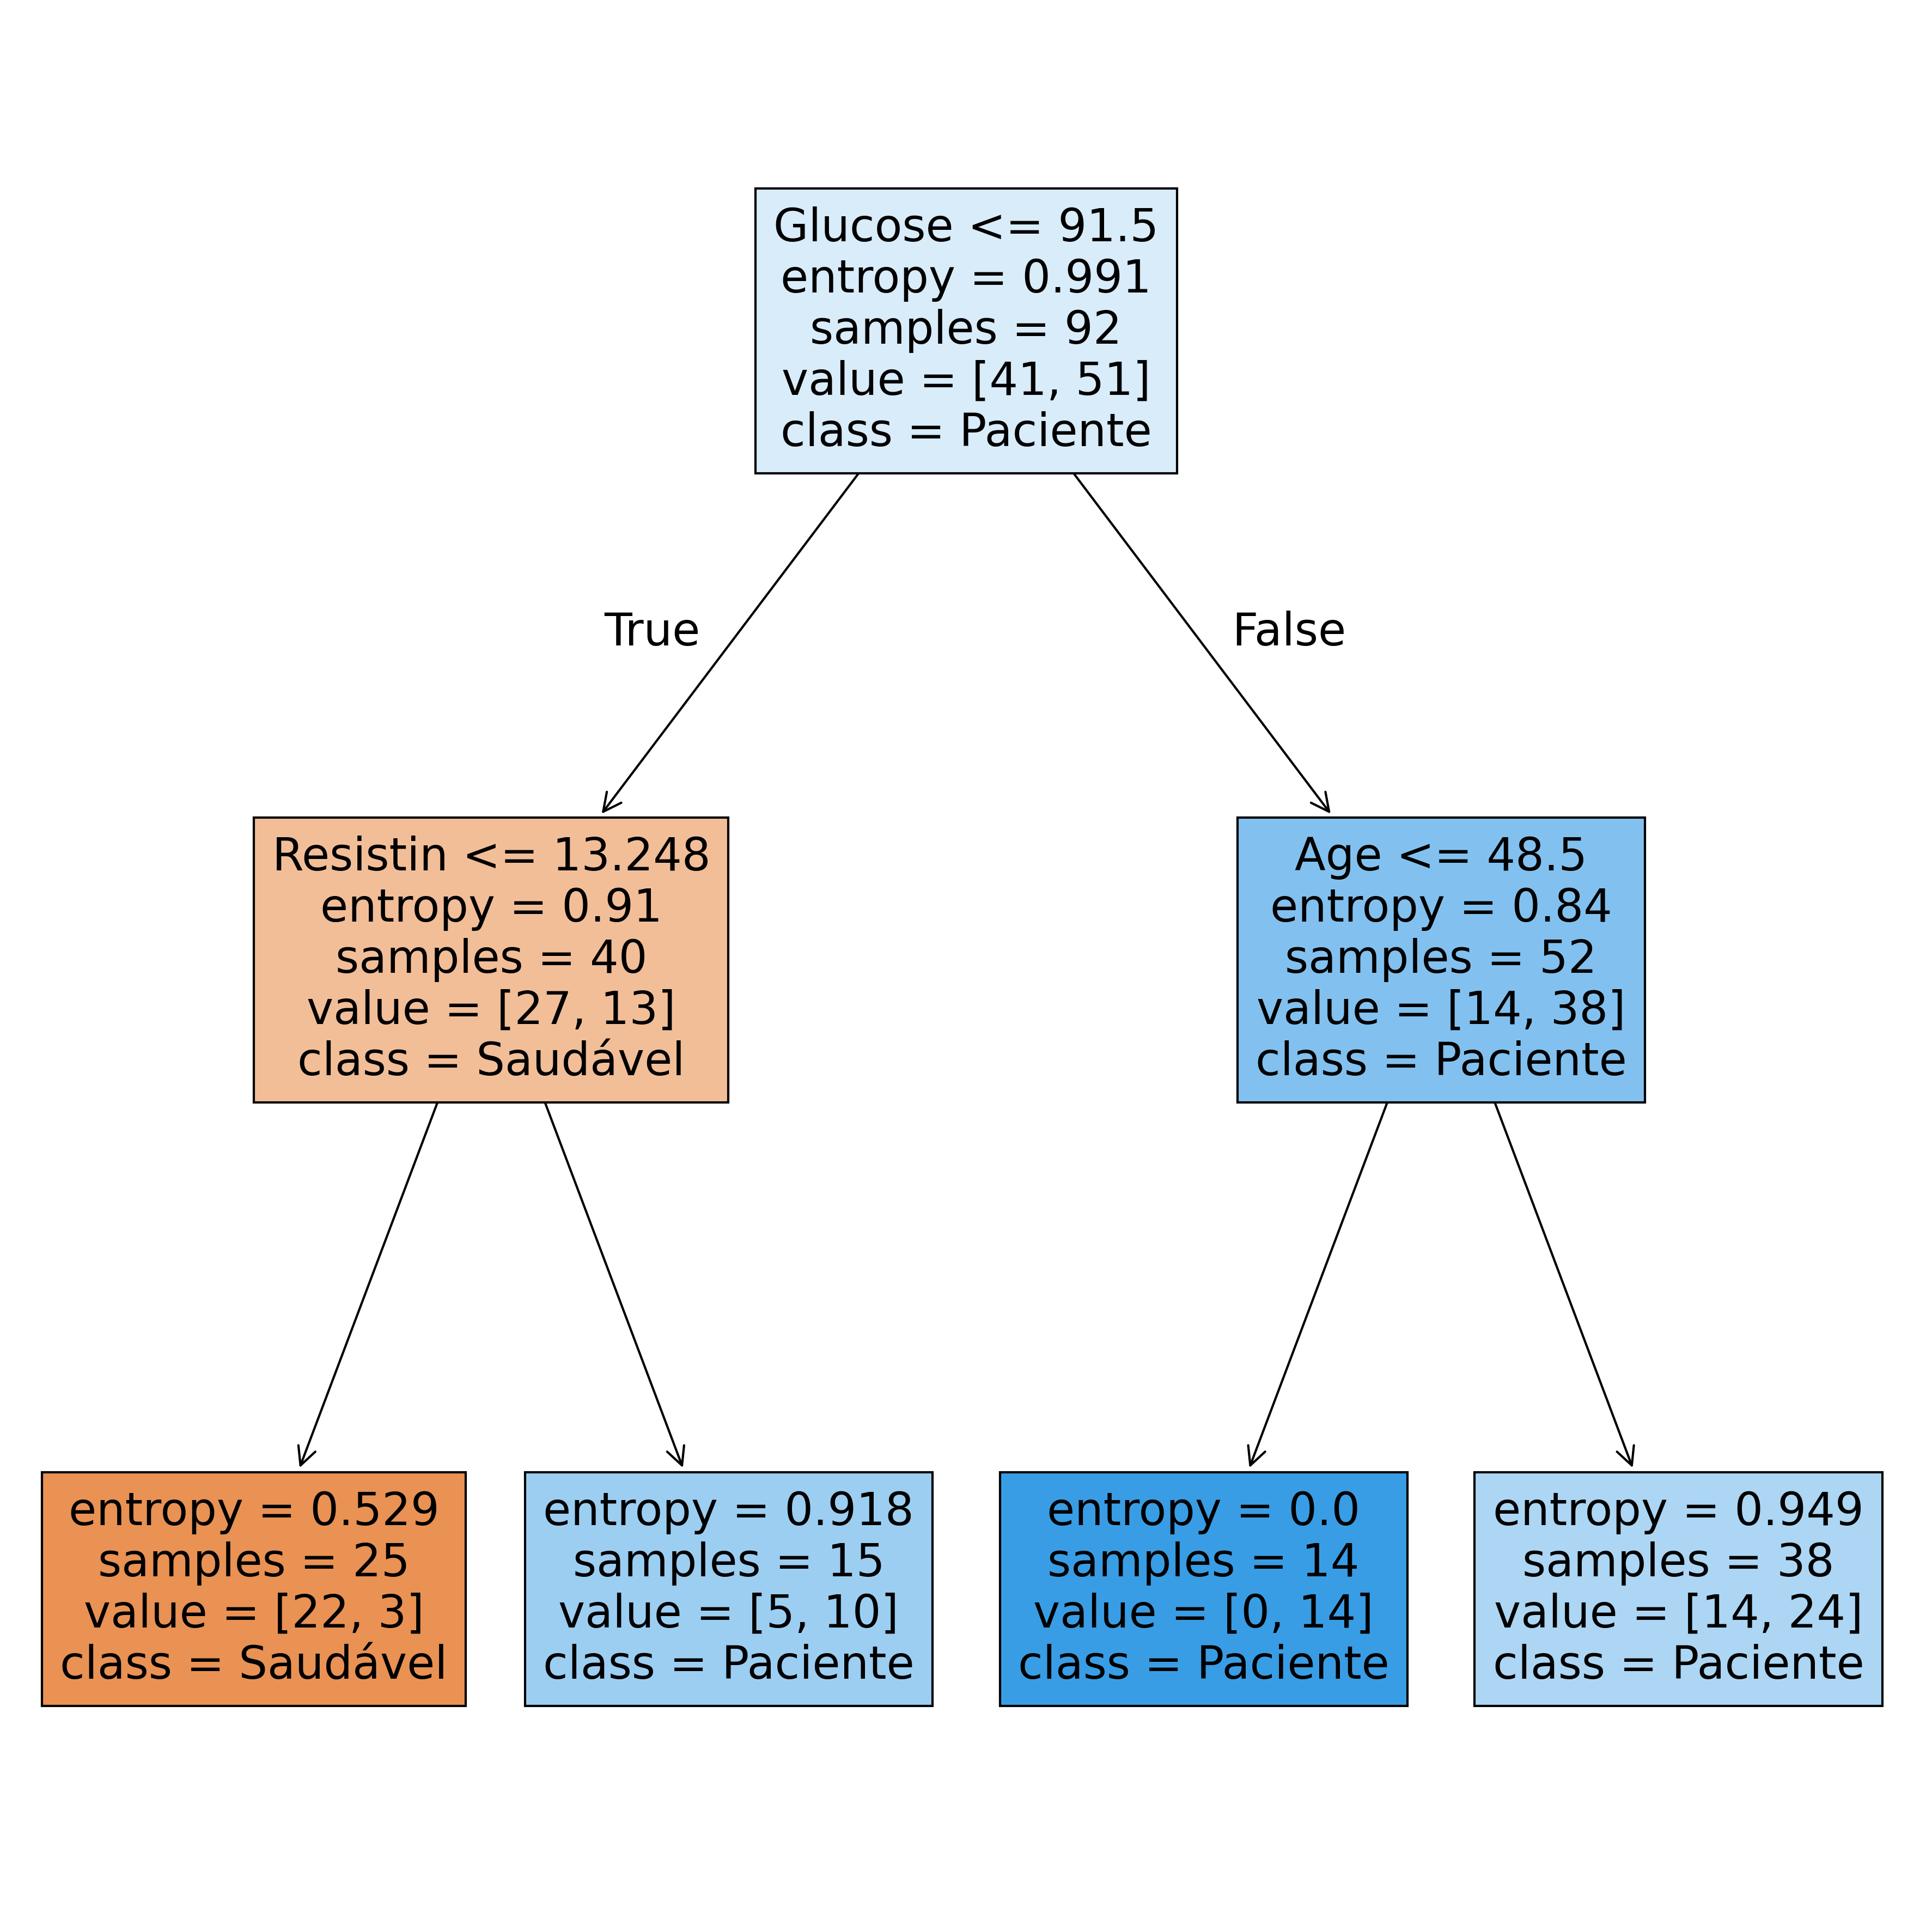

In [21]:
# Mapeando as classes do dataset Coimbra (1: Saudável, 2: Paciente com Câncer)
class_names = ['Saudável', 'Paciente']
label_names = list(X.columns)

fig, ax = plt.subplots(figsize=(15, 15), dpi=300)

tree.plot_tree(dt,
               feature_names=label_names,
               class_names=class_names,
               filled=True,
               ax=ax)
fig.savefig('arvore_decisao.png', bbox_inches='tight')
plt.show()

In [22]:
print(accuracy_score(y_test, y_predito))

0.7083333333333334


In [28]:
rf = RandomForestClassifier(n_estimators=5, max_depth=2, random_state=7)
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=2, n_estimators=5, random_state=7)

In [24]:
estimator = rf.estimators_

In [25]:
y_predito_random_forest = rf.predict(x_test)

In [26]:
print(accuracy_score(y_test, y_predito_random_forest))

0.6666666666666666


In [29]:
class_names = ['Maligno', 'Benigno']
label_names = [
    'mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness',
    'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension',
    'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error',
    'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error',
    'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness',
    'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension'
]

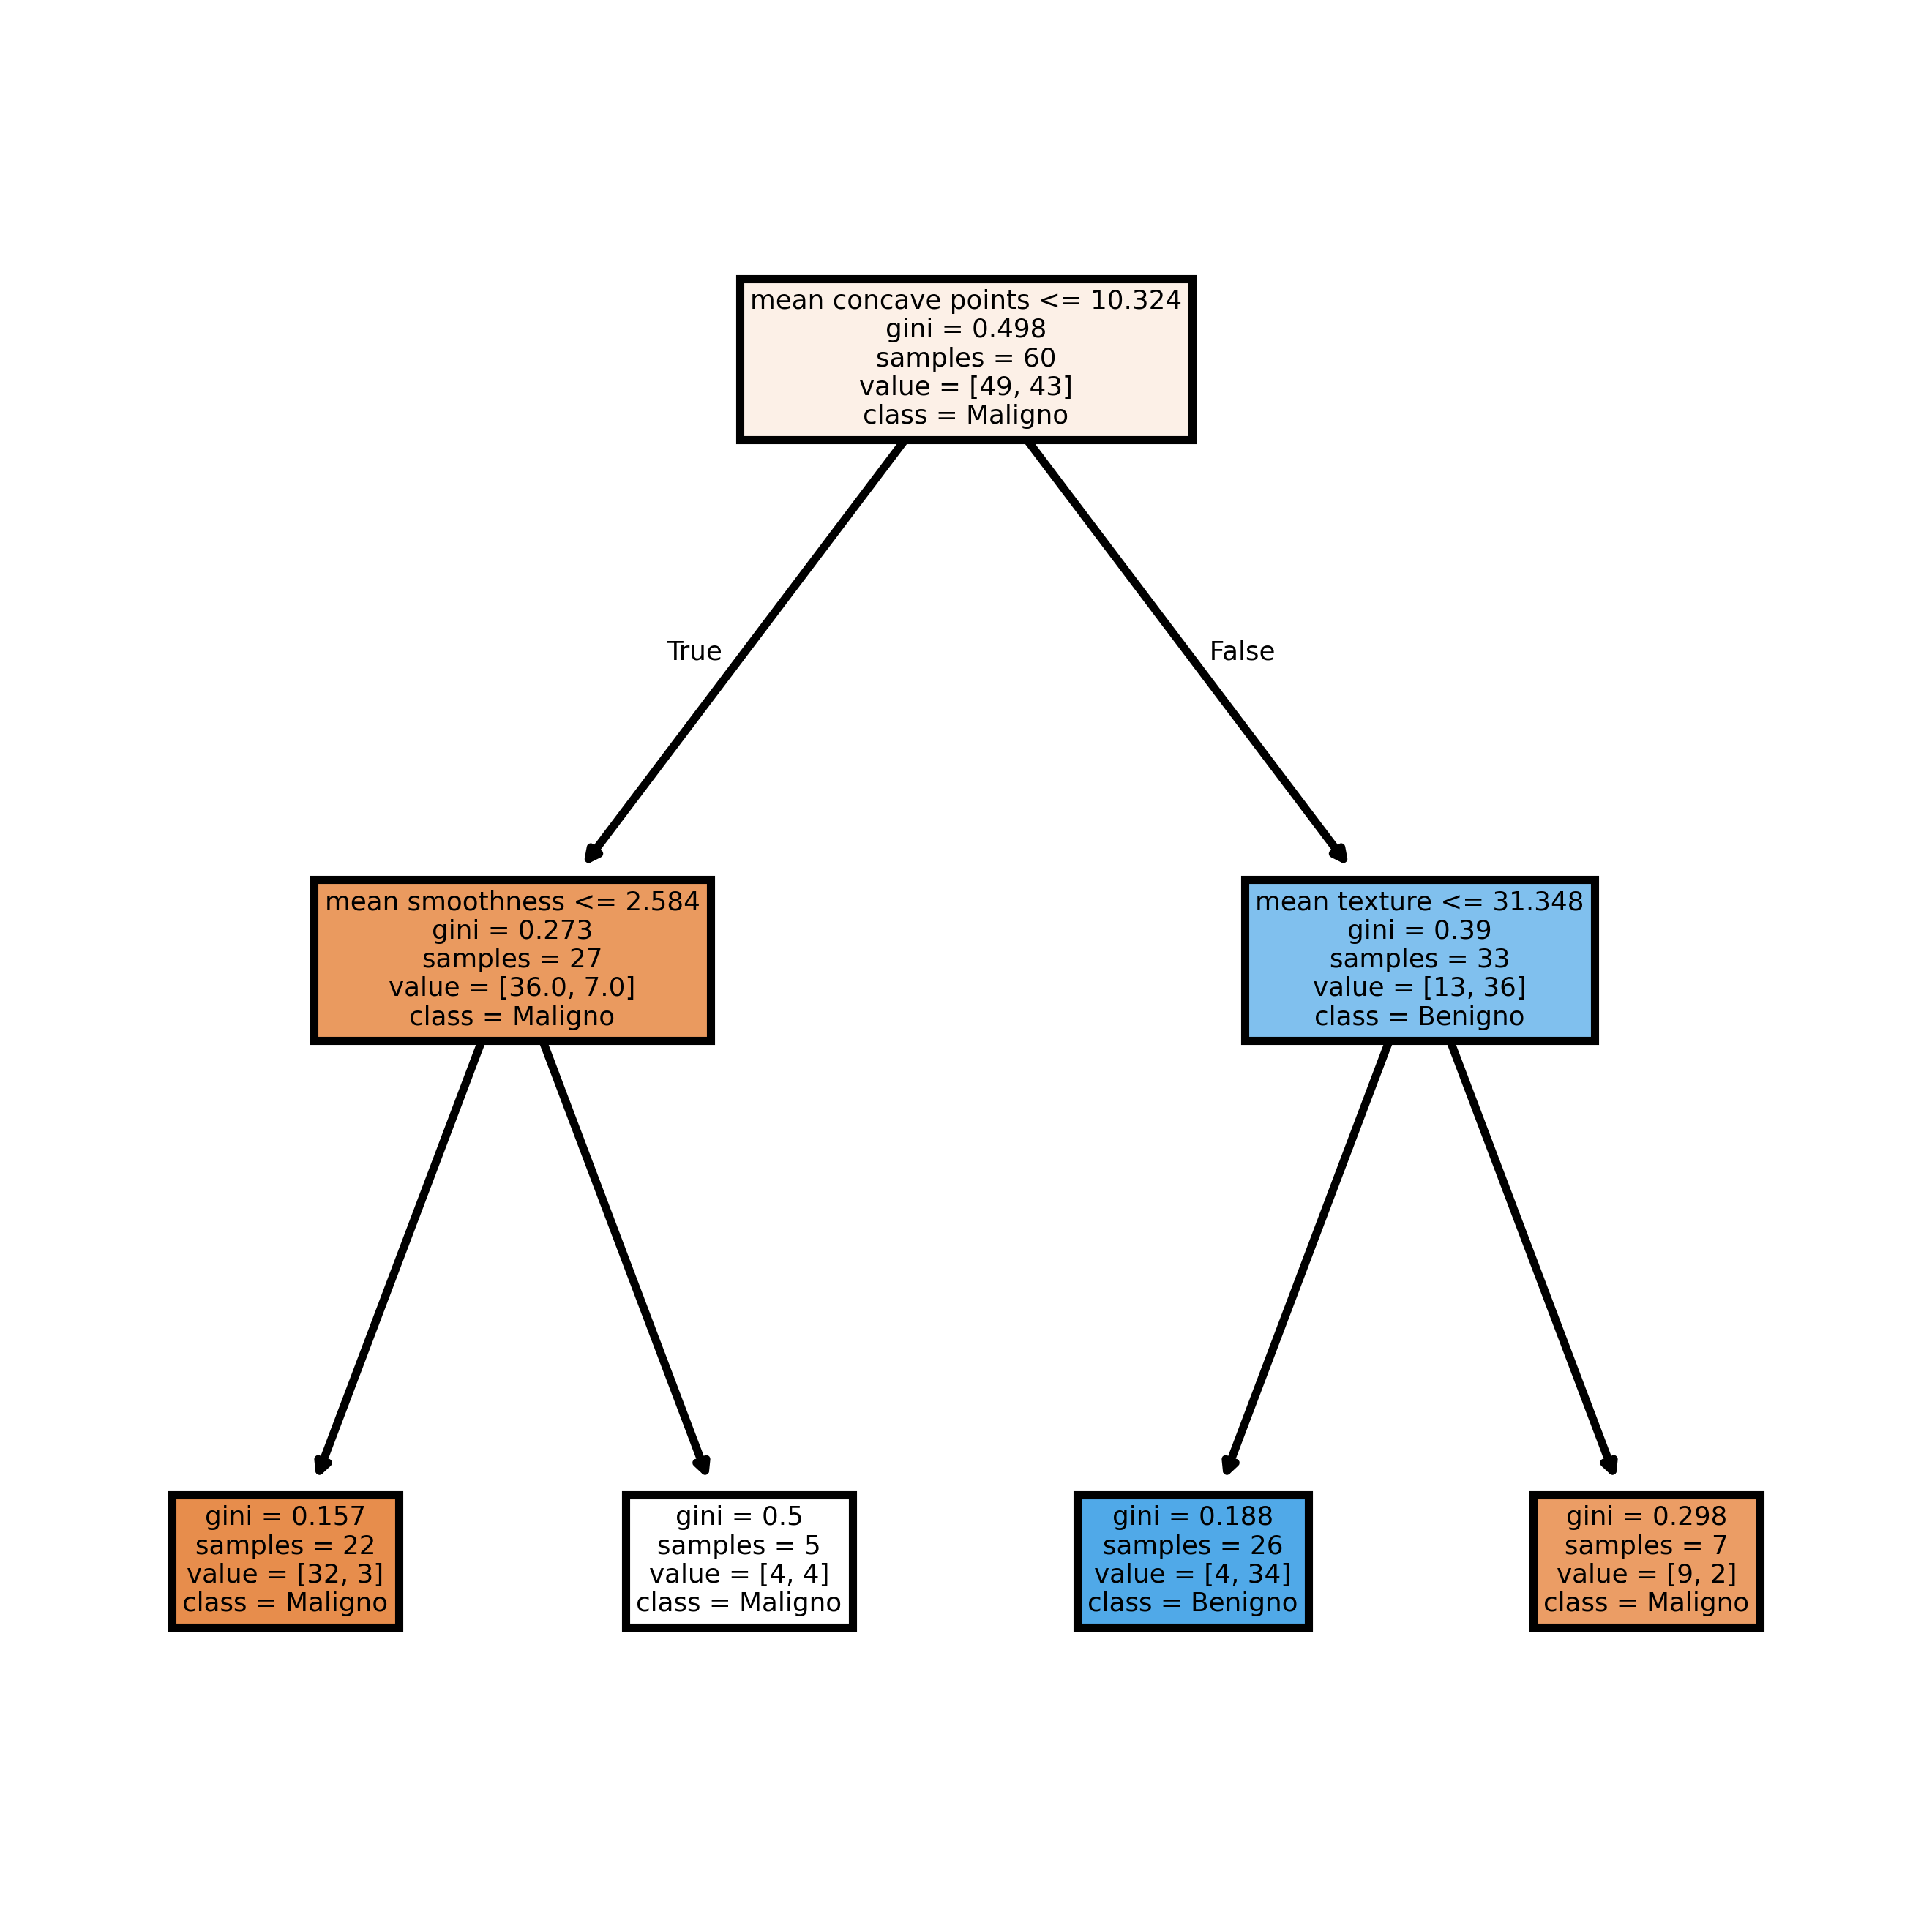

In [30]:
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=800)
tree.plot_tree(rf.estimators_[0],
               feature_names = label_names,
               class_names=class_names,
               filled = True);
fig.savefig('rf_individualtree.png')

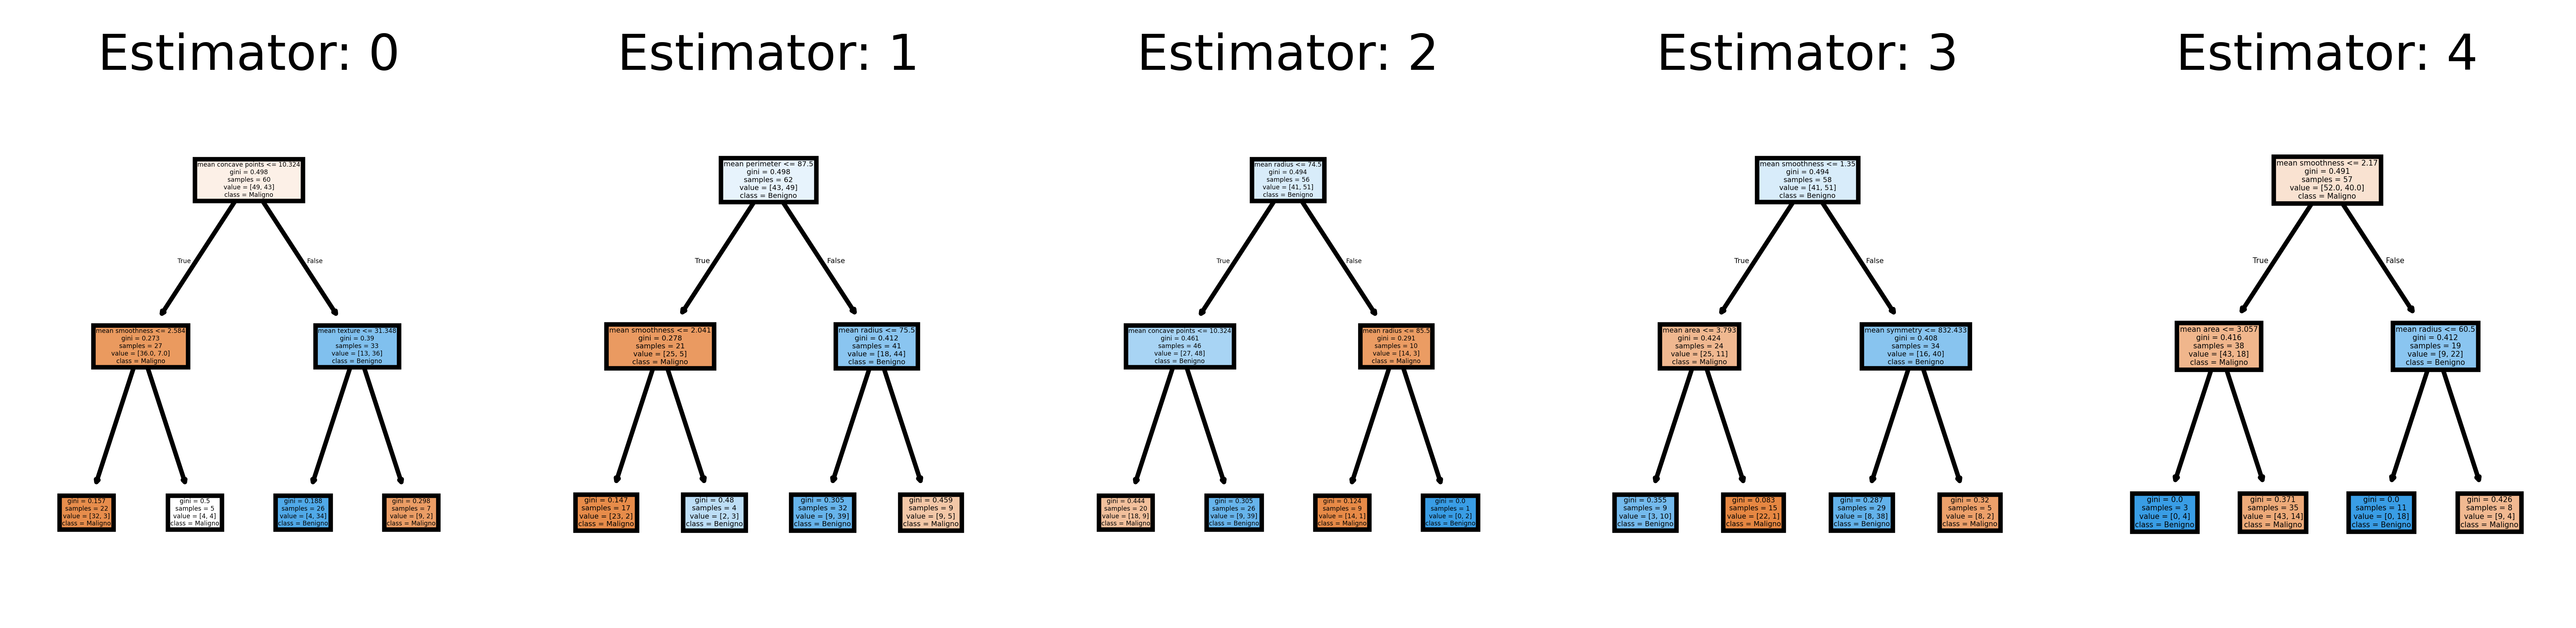

In [31]:
fig, axes = plt.subplots(nrows = 1,ncols = 5,figsize = (10,2), dpi=900)
for index in range(0, 5):
    tree.plot_tree(rf.estimators_[index],
                   feature_names = label_names,
                   class_names=class_names,
                   filled = True,
                   ax = axes[index]);

    axes[index].set_title('Estimator: ' + str(index), fontsize = 11)
fig.savefig('rf_5trees.png')

In [32]:
print (rf.score(x_train, y_train))
print(rf.score(x_test, y_test))

0.8369565217391305
0.6666666666666666


In [33]:
from sklearn.metrics import classification_report, confusion_matrix

y_predito_random_forest = rf.predict(x_test)

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_predito_random_forest))

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_predito_random_forest, target_names=class_names))

Matriz de Confusão:
[[7 4]
 [4 9]]

Relatório de Classificação:
              precision    recall  f1-score   support

     Maligno       0.64      0.64      0.64        11
     Benigno       0.69      0.69      0.69        13

    accuracy                           0.67        24
   macro avg       0.66      0.66      0.66        24
weighted avg       0.67      0.67      0.67        24



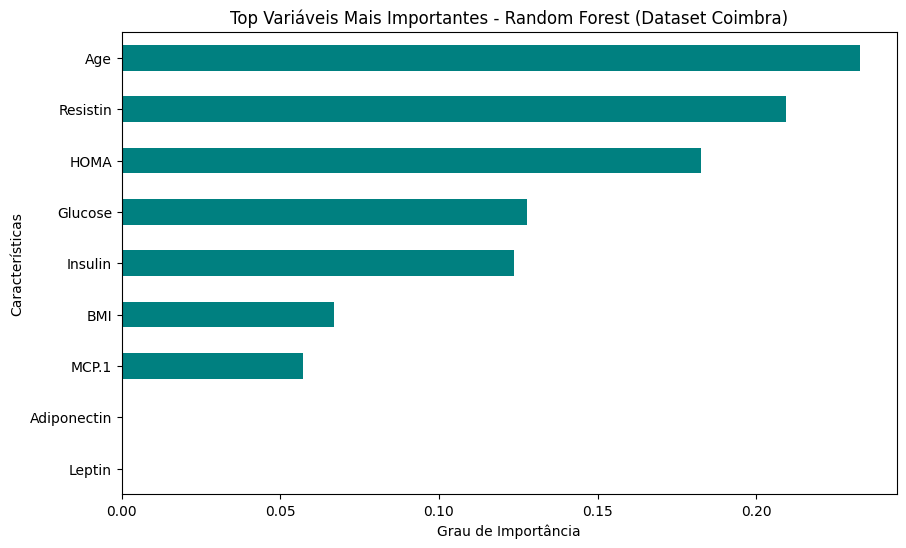

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# Extrair a importância de cada feature usando as colunas reais do conjunto de dados de treino (9 colunas)
importances = pd.Series(rf.feature_importances_, index=X.columns)

# Plotar as variáveis mais importantes
plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top Variáveis Mais Importantes - Random Forest (Dataset Coimbra)')
plt.xlabel('Grau de Importância')
plt.ylabel('Características')
plt.gca().invert_yaxis() # Inverter para a mais importante ficar no topo
plt.show()

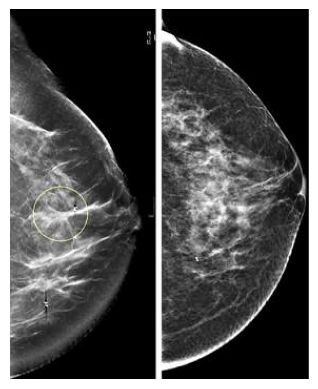

In [37]:
from PIL import Image
import matplotlib.pyplot as plt

# Carregar a imagem correta existente no ambiente
caminho_imagem = "images.jpg"
imagem = Image.open(caminho_imagem)

# Exibir a imagem na tela
plt.imshow(imagem, cmap="gray") # Imagens de raio-X/mamografia geralmente usam escala de cinza
plt.axis("off")
plt.show()

In [39]:
import numpy as np

img_array = np.array(imagem)
img_array.shape

(352, 284, 3)

In [40]:
def filtro_kmeans(img, clusters):
    vectorized = img.reshape((-1,1))
    kmeans = KMeans(n_clusters=clusters, random_state = 0, n_init=5)
    kmeans.fit(vectorized)

    centers = np.uint8(kmeans.cluster_centers_)
    segmented_data = centers[kmeans.labels_.flatten()]

    segmented_image = segmented_data.reshape((img.shape))
    return(segmented_image)

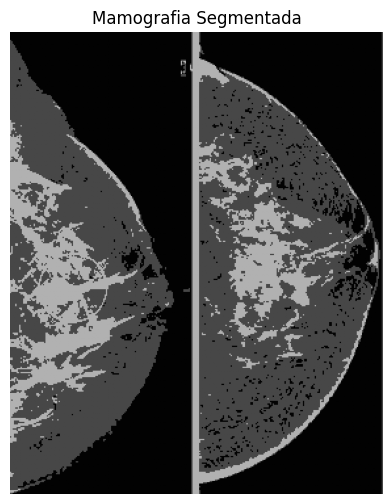

In [51]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. Função K-Means para imagens em tons de cinza
def filtro_kmeans(img, clusters):
    h, w = img.shape
    vectorized = img.reshape((-1, 1))

    kmeans = KMeans(n_clusters=clusters, random_state=0, n_init=5)
    kmeans.fit(vectorized)

    centers = np.uint8(kmeans.cluster_centers_)
    segmented_data = centers[kmeans.labels_.flatten()]

    segmented_image = segmented_data.reshape((h, w))
    return segmented_image

# 2. Aplicando o filtro com 3 clusters direto na imagem que contém os dois lados
clusters = 3
img_segmentada = filtro_kmeans(img_G, clusters) # Substituído 'sua_imagem' por 'img_G' que existe no Kernel

# 3. Exibindo apenas a imagem única segmentada
plt.figure(figsize=(6, 6))
plt.imshow(img_segmentada, cmap='gray', vmin=0, vmax=255)
plt.title("Mamografia Segmentada")
plt.axis('off')
plt.show()